# 04 · Modelado — Dry Bean Dataset
**CRISP-DM fase 4: Modelado** · Sprint 2 · Backlog: PB-03, PB-04, PB-05


| **Entrada** | `drybean_clean.csv` — datos limpios |
| **Entrada** | `labelencoder.joblib` — codificador de la clase de frijoles |
| **Salida** | `modelo_logistica.joblib`, `modelo_xgboost.joblib` — pipelines entrenados |
| **Salida** | `metricas_modelos.csv`, `predicciones_test.csv` — insumos para la etapa de evaluacion |

El notebook sigue las siguientes tareas: **seleccionar la técnica, generar el diseño de prueba, construir los modelos y evaluarlos técnicamente**. La decisión sobre qué modelo se aprueba para el negocio se toma en la etapa de (Evaluación).

## 0. Entorno y datos

In [39]:


import sys
import json
import warnings
from importlib.metadata import version

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, learning_curve
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score, precision_score,
                             recall_score, cohen_kappa_score, log_loss, classification_report,
                             ConfusionMatrixDisplay)
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline
from xgboost import XGBClassifier

warnings.filterwarnings("ignore", category=UserWarning)
RANDOM_STATE = 42

print("Python:", sys.version.split()[0])
for lib in ["pandas", "numpy", "scikit-learn", "imbalanced-learn", "xgboost", "joblib"]:
    print(f"{lib}: {version(lib)}")

Python: 3.13.18
pandas: 2.2.3
numpy: 2.4.6
scikit-learn: 1.6.1
imbalanced-learn: 0.14.2
xgboost: 3.4.1
joblib: 1.6.0


In [40]:
import os

# Definir la ruta local de los archivos
RUTA = os.path.join("Datos", "Datos Limpios")

# Cargar el dataset limpio
df = pd.read_csv(os.path.join(RUTA, "drybean_clean.csv"))

# Cargar el Label Encoder
label_encoder = joblib.load(os.path.join(RUTA, "labelencoder.joblib"))

# Obtener las clases
CLASES = list(label_encoder.classes_)

print("Datos:", df.shape)
print("Clases:", dict(enumerate(CLASES)))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Datos: (13543, 18)
Clases: {0: 'BARBUNYA', 1: 'BOMBAY', 2: 'CALI', 3: 'DERMASON', 4: 'HOROZ', 5: 'SEKER', 6: 'SIRA'}


---
# Tarea 1 · Seleccionar la técnica de modelado

| Modelo | Rol | Por qué se incluye |
| --- | --- | --- |
| `DummyClassifier` | Piso de referencia | Siempre predice la clase más frecuente (DERMASON). Muestra cuánto aporta un modelo real frente a no tener modelo |
| Regresión logística | **Baseline** | Es simple y rápido|
| XGBoost | **Modelo alternativo**  |

**Supuestos de cada técnica:**
- **Regresión logística:** separa las clases con fronteras lineales y es sensible a la escala de las variables, por eso necesita `StandardScaler`. La alta correlación entre variables (ver EDA) puede volver inestables sus coeficientes, pero no suele afectar sus predicciones.
- **XGBoost:** combina cientos de árboles de decisión; capta relaciones no lineales y no necesita escalado. Tolera bien variables redundantes.

In [41]:
PARAMS_LOGISTICA = {"max_iter": 1000, "random_state": RANDOM_STATE}

PARAMS_XGBOOST = {                     #
    "n_estimators": 100,
    "learning_rate": 0.3,
    "max_depth": 6,
    "subsample": 1.0,
    "colsample_bytree": 1.0,
    "objective": "multi:softprob",
    "random_state": RANDOM_STATE,      # agregado para reproducibilidad
}
pd.DataFrame({"valor": PARAMS_XGBOOST})

,valor
n_estimators,100
learning_rate,0.3
max_depth,6
subsample,1.0
colsample_bytree,1.0
objective,multi:softprob
random_state,42


---
# Tarea 2 · Generar el diseño de prueba

**Cómo se medirá la calidad de los modelos:**

1. **Partición 80/20 estratificada** (`random_state=42`). El 20 % de prueba **no se usa para entrenar ni para tomar decisiones**: solo para la evaluación final.
2. **Validación cruzada estratificada de 5 particiones** sobre el 80 % de entrenamiento, para medir la estabilidad.
3. **Métricas:**

| Métrica | Qué mide | Rol |
| --- | --- | --- |
| **F1 macro** | Promedio del F1 de cada clase, con el mismo peso | **Principal** (las clases están desbalanceadas) |
| Accuracy | Porcentaje de granos bien clasificados | Complementaria, fácil de comunicar |
| Balanced accuracy | Promedio del recall de cada clase | Complementaria; no se deja llevar por las clases grandes |
| Precision / recall macro | Exactitud de lo que predice / capacidad de encontrar cada clase | Diagnóstico |
| Kappa de Cohen | Acuerdo con la clase real descontando el azar (1 = perfecto, 0 = azar) | Complementaria |
| Log loss | Calidad de las probabilidades (más bajo es mejor) | Diagnóstico |

In [42]:
FEATURES = [c for c in df.columns if c not in ("Class", "Class_cod")]
X = df[FEATURES]
y = df["Class_cod"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
print("Entrenamiento:", X_train.shape, "| Prueba:", X_test.shape)

pd.DataFrame({
    "% train": (y_train.value_counts(normalize=True).sort_index() * 100).round(1).values,
    "% test": (y_test.value_counts(normalize=True).sort_index() * 100).round(1).values,
}, index=CLASES)

Entrenamiento: (10834, 16) | Prueba: (2709, 16)


,% train,% test
BARBUNYA,9.8,9.8
BOMBAY,3.9,3.8
CALI,12.0,12.0
DERMASON,26.2,26.2
HOROZ,13.7,13.7
SEKER,15.0,15.0
SIRA,19.5,19.5


In [43]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def calcular_metricas(y_real, y_pred, y_proba=None):
    m = {
        "accuracy": accuracy_score(y_real, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y_real, y_pred),
        "f1_macro": f1_score(y_real, y_pred, average="macro"),
        "precision_macro": precision_score(y_real, y_pred, average="macro", zero_division=0),
        "recall_macro": recall_score(y_real, y_pred, average="macro"),
        "cohen_kappa": cohen_kappa_score(y_real, y_pred),
    }
    m["log_loss"] = log_loss(y_real, y_proba, labels=range(len(CLASES))) if y_proba is not None else np.nan
    return m

---
# Tarea 3 · Construir los modelos

Cada modelo real es un **pipeline**:

**SMOTE → StandardScaler → algoritmo**

- Así la comparación es justa: mismos datos y misma preparación; solo cambia el algoritmo.
- Al entrenar, SMOTE crea granos sintéticos y el scaler se ajusta, **solo con entrenamiento**.
- Al predecir, SMOTE se omite automáticamente; solo se aplica el scaler ya ajustado.
- En la validación cruzada, el pipeline repite todo dentro de cada partición: no hay fuga de información.

In [44]:
modelos = {
    "Dummy (clase más frecuente)": DummyClassifier(strategy="most_frequent"),
    "Regresión logística": Pipeline([
        ("smote", SMOTE(random_state=RANDOM_STATE)),
        ("scaler", StandardScaler()),
        ("modelo", LogisticRegression(**PARAMS_LOGISTICA)),
    ]),
    "XGBoost": Pipeline([
        ("smote", SMOTE(random_state=RANDOM_STATE)),
        ("scaler", StandardScaler()),
        ("modelo", XGBClassifier(**PARAMS_XGBOOST)),
    ]),
}

for nombre, modelo in modelos.items():
    modelo.fit(X_train, y_train)
    print("Entrenado:", nombre)

Entrenado: Dummy (clase más frecuente)
Entrenado: Regresión logística
Entrenado: XGBoost


---
# Tarea 4 · Evaluar los modelos (evaluación técnica)

## 4.1 Validación cruzada (estabilidad)

In [45]:
filas = []
for nombre, modelo in modelos.items():
    res = cross_validate(modelo, X_train, y_train, cv=cv,
                         scoring=["accuracy", "f1_macro", "balanced_accuracy"], n_jobs=-1)
    filas.append({
        "modelo": nombre,
        "f1_macro_media": res["test_f1_macro"].mean(),
        "f1_macro_desv": res["test_f1_macro"].std(),
        "accuracy_media": res["test_accuracy"].mean(),
        "balanced_acc_media": res["test_balanced_accuracy"].mean(),
    })
cv_resultados = pd.DataFrame(filas).set_index("modelo")
cv_resultados.round(4)

,f1_macro_media,f1_macro_desv,accuracy_media,balanced_acc_media
modelo,,,,
Dummy (clase más frecuente),0.0593,0.0000,0.2619,0.1429
Regresión logística,0.9330,0.0055,0.9194,0.9339
XGBoost,0.9381,0.0042,0.9260,0.9378


## 4.2 Métricas en el conjunto de prueba

In [46]:
predicciones = {}
filas = []
for nombre, modelo in modelos.items():
    y_pred = modelo.predict(X_test)
    y_proba = modelo.predict_proba(X_test) if "Dummy" not in nombre else None
    predicciones[nombre] = y_pred
    filas.append({"modelo": nombre, **calcular_metricas(y_test, y_pred, y_proba)})

metricas_test = pd.DataFrame(filas).set_index("modelo")
metricas_test.round(4)

,accuracy,balanced_accuracy,f1_macro,precision_macro,recall_macro,cohen_kappa,log_loss
modelo,,,,,,,
Dummy (clase más frecuente),0.2617,0.1429,0.0593,0.0374,0.1429,0.0000,NaN
Regresión logística,0.9151,0.9292,0.9277,0.9270,0.9292,0.8975,0.2236
XGBoost,0.9169,0.9289,0.9292,0.9296,0.9289,0.8996,0.2599


El log loss del Dummy no se calcula: asigna probabilidad 1 a una sola clase, así que su valor no es comparable.

## 4.3 Reporte por clase

In [47]:
for nombre in ["Regresión logística", "XGBoost"]:
    print(f"===== {nombre} =====")
    print(classification_report(y_test, predicciones[nombre], target_names=CLASES, digits=3))

===== Regresión logística =====
              precision    recall  f1-score   support

    BARBUNYA      0.915     0.898     0.907       265
      BOMBAY      1.000     1.000     1.000       104
        CALI      0.911     0.945     0.928       326
    DERMASON      0.940     0.879     0.908       709
       HOROZ      0.967     0.944     0.955       372
       SEKER      0.921     0.946     0.933       406
        SIRA      0.835     0.894     0.863       527

    accuracy                          0.915      2709
   macro avg      0.927     0.929     0.928      2709
weighted avg      0.917     0.915     0.915      2709

===== XGBoost =====
              precision    recall  f1-score   support

    BARBUNYA      0.916     0.902     0.909       265
      BOMBAY      1.000     1.000     1.000       104
        CALI      0.924     0.936     0.930       326
    DERMASON      0.915     0.907     0.911       709
       HOROZ      0.964     0.941     0.952       372
       SEKER      0.932   

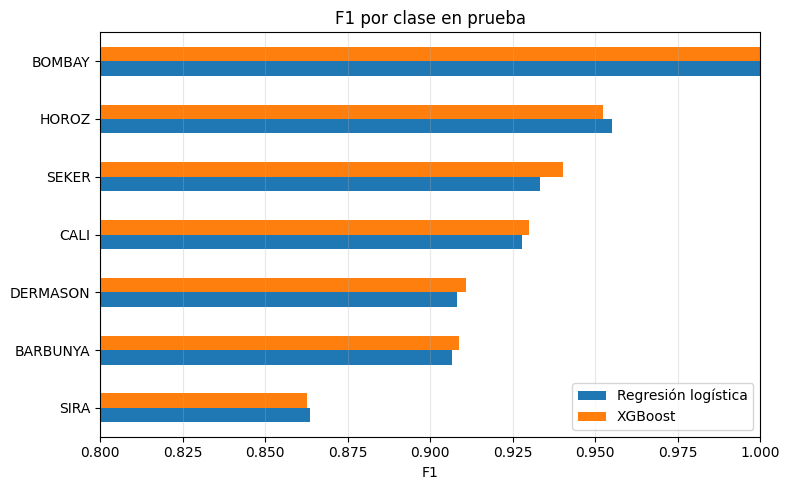

In [48]:
f1_clase = pd.DataFrame({
    nombre: f1_score(y_test, predicciones[nombre], average=None)
    for nombre in ["Regresión logística", "XGBoost"]
}, index=CLASES).sort_values("XGBoost")

f1_clase.plot(kind="barh", figsize=(8, 5))
plt.title("F1 por clase en prueba")
plt.xlabel("F1")
plt.xlim(0.8, 1.0)
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

## 4.4 Matrices de confusión

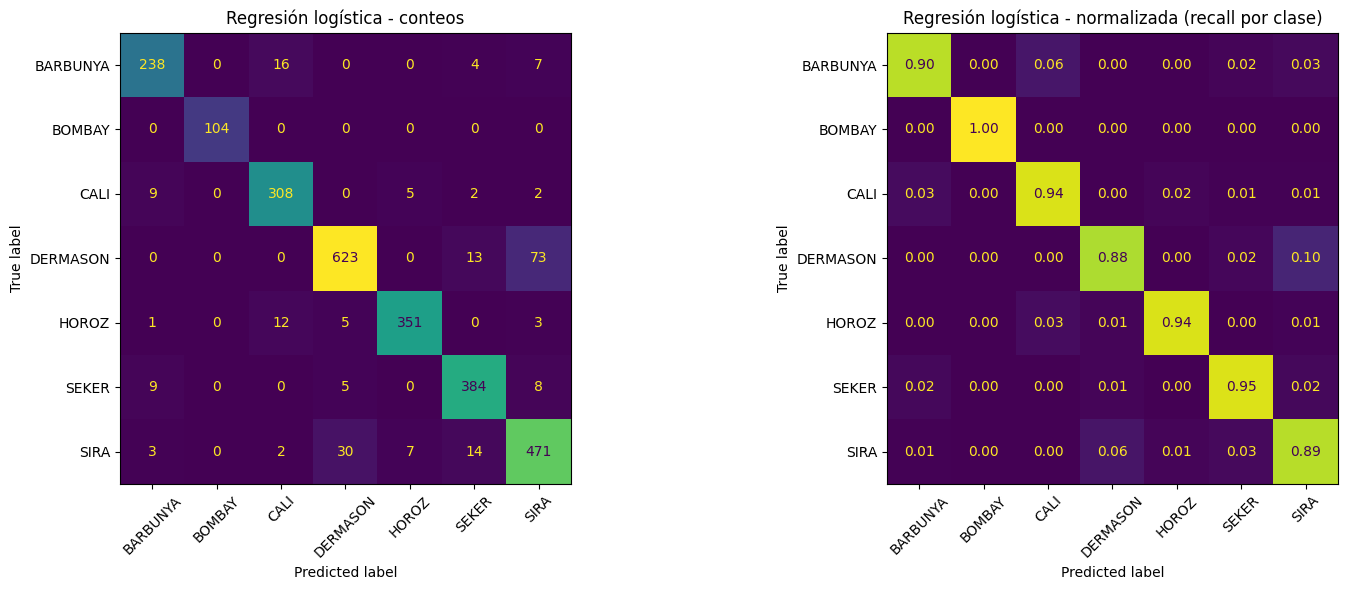

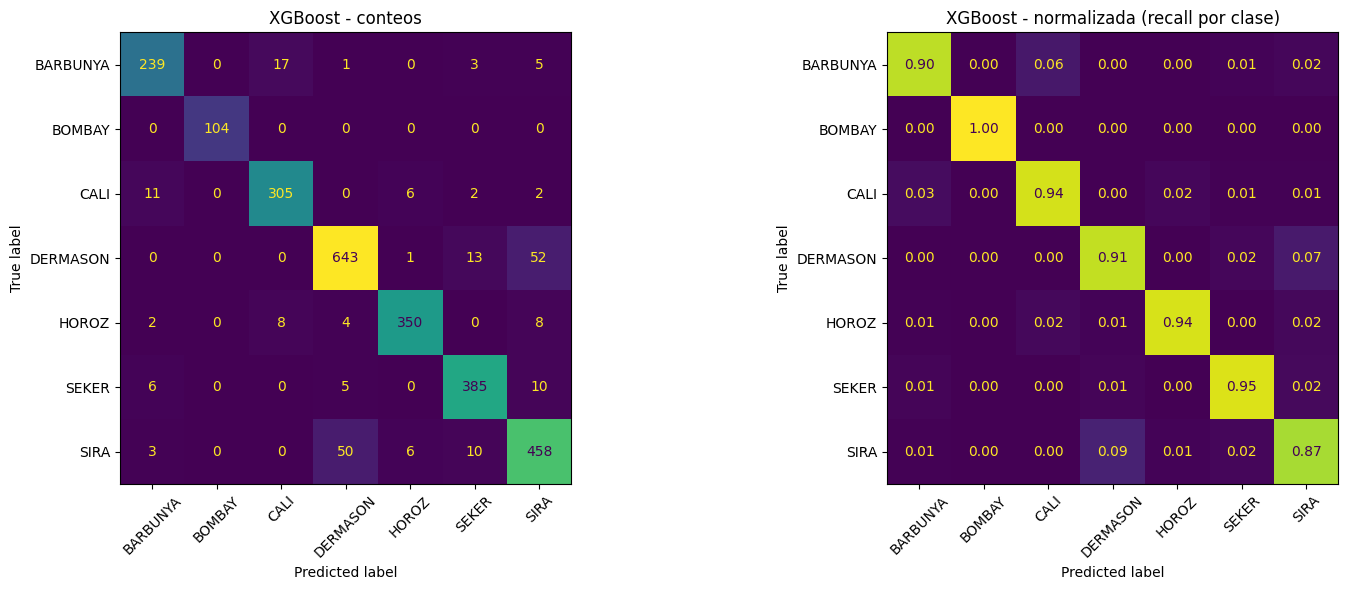

In [49]:
for nombre in ["Regresión logística", "XGBoost"]:
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    ConfusionMatrixDisplay.from_predictions(y_test, predicciones[nombre], display_labels=CLASES,
                                            xticks_rotation=45, ax=axes[0], colorbar=False)
    axes[0].set_title(f"{nombre} - conteos")
    ConfusionMatrixDisplay.from_predictions(y_test, predicciones[nombre], display_labels=CLASES,
                                            xticks_rotation=45, normalize="true", values_format=".2f",
                                            ax=axes[1], colorbar=False)
    axes[1].set_title(f"{nombre} - normalizada (recall por clase)")
    plt.tight_layout()
    plt.show()

In [50]:
# Pares de clases que más se confunden (sumando ambos sentidos)
def pares_confundidos(y_real, y_pred):
    cm = pd.crosstab(pd.Series(label_encoder.inverse_transform(y_real), name="real"),
                     pd.Series(label_encoder.inverse_transform(y_pred), name="pred"))
    cm = cm.reindex(index=CLASES, columns=CLASES, fill_value=0)
    return {f"{a} ↔ {b}": cm.loc[a, b] + cm.loc[b, a]
            for i, a in enumerate(CLASES) for b in CLASES[i + 1:]}

pd.DataFrame({nombre: pares_confundidos(y_test, predicciones[nombre])
              for nombre in ["Regresión logística", "XGBoost"]}) \
  .sort_values("XGBoost", ascending=False).head(5)

,Regresión logística,XGBoost
DERMASON ↔ SIRA,103,102
BARBUNYA ↔ CALI,25,28
SEKER ↔ SIRA,22,20
DERMASON ↔ SEKER,18,18
CALI ↔ HOROZ,17,14


## 4.5 Entrenamiento vs. prueba (¿sobreajuste?)
Las métricas de entrenamiento se calculan sobre los granos **reales** de entrenamiento (sin los sintéticos de SMOTE), para comparar en igualdad de condiciones con prueba.

In [51]:
filas = []
for nombre in ["Regresión logística", "XGBoost"]:
    modelo = modelos[nombre]
    f1_train = f1_score(y_train, modelo.predict(X_train), average="macro")
    f1_test = metricas_test.loc[nombre, "f1_macro"]
    filas.append({"modelo": nombre, "f1_macro_train": f1_train,
                  "f1_macro_test": f1_test, "brecha": f1_train - f1_test})
brecha = pd.DataFrame(filas).set_index("modelo")
brecha.round(4)

,f1_macro_train,f1_macro_test,brecha
modelo,,,
Regresión logística,0.9348,0.9277,0.0071
XGBoost,0.9999,0.9292,0.0707


## 4.6 Curva por número de árboles (XGBoost)
Cómo cambia el error a medida que XGBoost agrega árboles. Se calcula **después** de entrenar, prediciendo con los primeros *k* árboles. El conjunto de prueba se usa solo para dibujar la curva: **no se usa para cambiar hiperparámetros**.

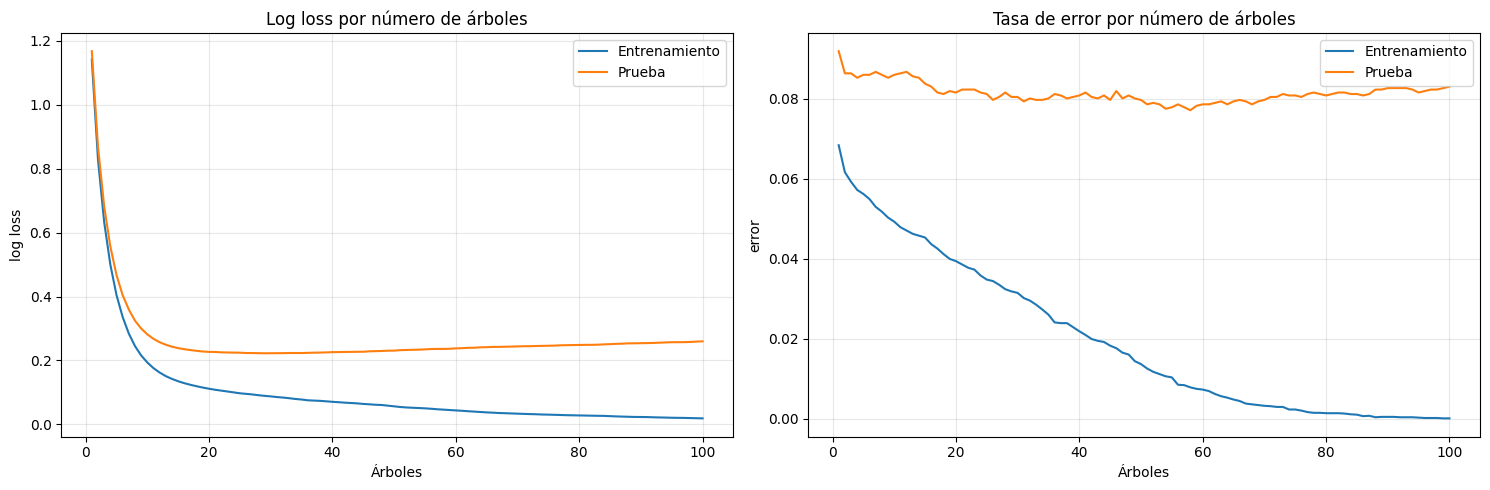

Log loss de prueba mínimo con 29 árboles: 0.2224
Log loss de prueba con 100 árboles: 0.2599


In [52]:
xgb_pipe = modelos["XGBoost"]
xgb = xgb_pipe.named_steps["modelo"]
X_train_esc = xgb_pipe.named_steps["scaler"].transform(X_train)
X_test_esc = xgb_pipe.named_steps["scaler"].transform(X_test)

arboles = range(1, PARAMS_XGBOOST["n_estimators"] + 1)
curva = {"ll_train": [], "ll_test": [], "err_train": [], "err_test": []}
for k in arboles:
    p_tr = xgb.predict_proba(X_train_esc, iteration_range=(0, k))
    p_te = xgb.predict_proba(X_test_esc, iteration_range=(0, k))
    curva["ll_train"].append(log_loss(y_train, p_tr))
    curva["ll_test"].append(log_loss(y_test, p_te))
    curva["err_train"].append(1 - accuracy_score(y_train, p_tr.argmax(axis=1)))
    curva["err_test"].append(1 - accuracy_score(y_test, p_te.argmax(axis=1)))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].plot(arboles, curva["ll_train"], label="Entrenamiento")
axes[0].plot(arboles, curva["ll_test"], label="Prueba")
axes[0].set(title="Log loss por número de árboles", xlabel="Árboles", ylabel="log loss")
axes[1].plot(arboles, curva["err_train"], label="Entrenamiento")
axes[1].plot(arboles, curva["err_test"], label="Prueba")
axes[1].set(title="Tasa de error por número de árboles", xlabel="Árboles", ylabel="error")
for ax in axes:
    ax.legend()
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

k_min = int(np.argmin(curva["ll_test"])) + 1
print(f"Log loss de prueba mínimo con {k_min} árboles: {min(curva['ll_test']):.4f}")
print(f"Log loss de prueba con {len(arboles)} árboles: {curva['ll_test'][-1]:.4f}")

## 4.7 Curvas de aprendizaje
F1 macro según la cantidad de datos de entrenamiento (10 % a 100 %), con validación cruzada de 5 particiones. El pipeline aplica SMOTE y el scaler dentro de cada partición.

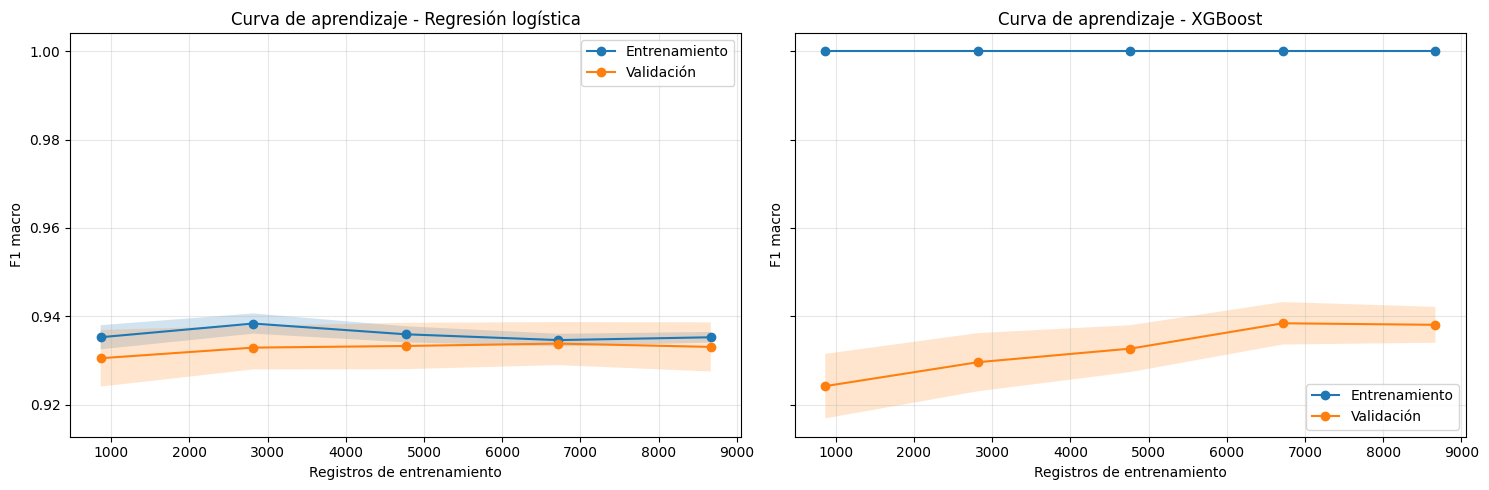

In [53]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)
for ax, nombre in zip(axes, ["Regresión logística", "XGBoost"]):
    tamanos, sc_train, sc_val = learning_curve(
        modelos[nombre], X_train, y_train, cv=cv, scoring="f1_macro",
        train_sizes=np.linspace(0.1, 1.0, 5), n_jobs=-1,
    )
    for scores, etiqueta in [(sc_train, "Entrenamiento"), (sc_val, "Validación")]:
        media, desv = scores.mean(axis=1), scores.std(axis=1)
        ax.plot(tamanos, media, marker="o", label=etiqueta)
        ax.fill_between(tamanos, media - desv, media + desv, alpha=0.2)
    ax.set(title=f"Curva de aprendizaje - {nombre}", xlabel="Registros de entrenamiento", ylabel="F1 macro")
    ax.legend()
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 4.8 Importancia de variables (XGBoost)

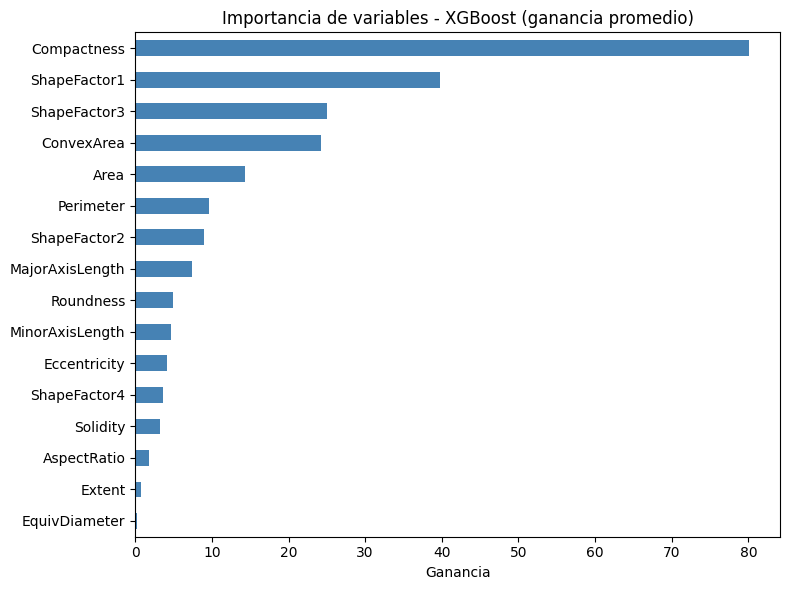

In [54]:
importancia = (
    pd.Series(xgb.get_booster().get_score(importance_type="gain"))
    .rename(index=lambda f: FEATURES[int(f[1:])] if f[1:].isdigit() else f)
    .sort_values()
)
importancia.plot(kind="barh", color="steelblue", figsize=(8, 6))
plt.title("Importancia de variables - XGBoost (ganancia promedio)")
plt.xlabel("Ganancia")
plt.tight_layout()
plt.show()

La **ganancia** mide cuánto mejora el modelo, en promedio, cada vez que un árbol usa esa variable. Como muchas variables están muy correlacionadas (ver EDA), la importancia se reparte entre ellas; no prueba causalidad.

## 4.9 Ranking técnico

In [55]:
ranking = pd.DataFrame({
    "f1_macro_test": metricas_test["f1_macro"],
    "accuracy_test": metricas_test["accuracy"],
    "f1_macro_cv": cv_resultados["f1_macro_media"],
    "f1_macro_cv_desv": cv_resultados["f1_macro_desv"],
    "brecha_train_test": brecha["brecha"],
}).sort_values("f1_macro_test", ascending=False)
ranking.round(4)

,f1_macro_test,accuracy_test,f1_macro_cv,f1_macro_cv_desv,brecha_train_test
modelo,,,,,
XGBoost,0.9292,0.9169,0.9381,0.0042,0.0707
Regresión logística,0.9277,0.9151,0.9330,0.0055,0.0071
Dummy (clase más frecuente),0.0593,0.2617,0.0593,0.0000,NaN


**Lectura técnica:**
- **Frente al Dummy:** el Dummy, que siempre predice DERMASON, logra F1 macro 0,059 y accuracy 0,262. La regresión logística (0,928) y XGBoost (0,929) lo superan por unos 0,87 puntos de F1 macro: los dos modelos aprenden patrones reales de los datos.
- **Logística vs. XGBoost:** en prueba, la diferencia de F1 macro es de solo 0,0015 (0,9292 vs. 0,9277). En validación cruzada, XGBoost queda 0,005 arriba (0,938 vs. 0,933), una diferencia del mismo tamaño que la desviación entre particiones (0,004 a 0,006). La diferencia no es significativa: los dos modelos rinden igual. Además, cometen los mismos errores: DERMASON ↔ SIRA (≈ 100 errores cada uno) y BARBUNYA ↔ CALI (≈ 25).
- **Sobreajuste:** XGBoost sobreajusta claramente. Su F1 macro en entrenamiento es 0,9999 frente a 0,929 en prueba (brecha 0,071), su curva de aprendizaje de entrenamiento se mantiene en 1,0 y el log loss de prueba es mínimo con 29 árboles y luego sube. La regresión logística casi no sobreajusta: brecha de 0,007, con curvas de entrenamiento y validación casi superpuestas.
- **Modelo candidato desde lo técnico: regresión logística.** Con desempeño equivalente, es el modelo más simple, más estable y sin sobreajuste. XGBoost no aporta una mejora que justifique su mayor complejidad.

La aprobación del modelo para el negocio se decide en la etapa de Evaluación.

---
## 5. Guardar resultados

In [56]:
import pickle

# Modelos en .joblib
joblib.dump(modelos["Regresión logística"], RUTA + "modelo_logistica.joblib")
joblib.dump(modelos["XGBoost"], RUTA + "modelo_xgboost.joblib")

# Modelos y LabelEncoder en .pkl
with open(RUTA + "modelo_logistica.pkl", "wb") as f:
    pickle.dump(modelos["Regresión logística"], f)
with open(RUTA + "modelo_xgboost.pkl", "wb") as f:
    pickle.dump(modelos["XGBoost"], f)
with open(RUTA + "labelencoder.pkl", "wb") as f:
    pickle.dump(label_encoder, f)

# Tabla de métricas
tabla = metricas_test.join(cv_resultados)
tabla.to_csv(RUTA + "metricas_modelos.csv")

# Predicciones sobre prueba (insumo del notebook 04)
pd.DataFrame({
    **{c: X_test[c].values for c in FEATURES},
    "real": label_encoder.inverse_transform(y_test),
    "pred_logistica": label_encoder.inverse_transform(predicciones["Regresión logística"]),
    "pred_xgboost": label_encoder.inverse_transform(predicciones["XGBoost"]),
}).to_csv(RUTA + "predicciones_test.csv", index=False)

archivos = [
    "modelo_logistica.joblib", "modelo_xgboost.joblib",
    "modelo_logistica.pkl", "modelo_xgboost.pkl", "labelencoder.pkl",
    "metricas_modelos.csv", "predicciones_test.csv",
]
print("Guardados en", RUTA)
for f in archivos:
    print(" -", f)

Guardados en /content/drive/MyDrive/
 - modelo_logistica.joblib
 - modelo_xgboost.joblib
 - modelo_logistica.pkl
 - modelo_xgboost.pkl
 - labelencoder.pkl
 - metricas_modelos.csv
 - predicciones_test.csv
